## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Sissi Wang]

**Date:** [10/12/2026]

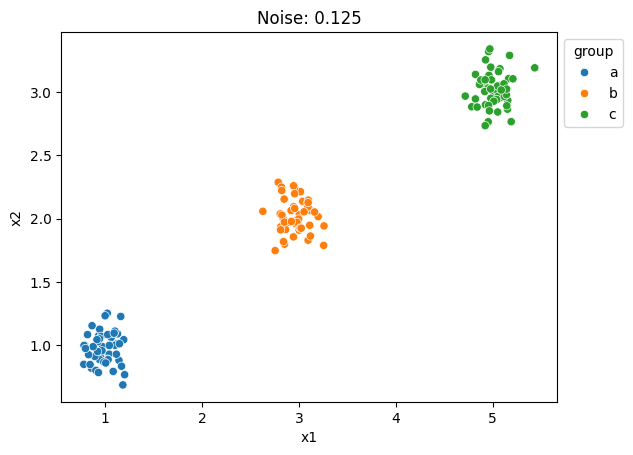

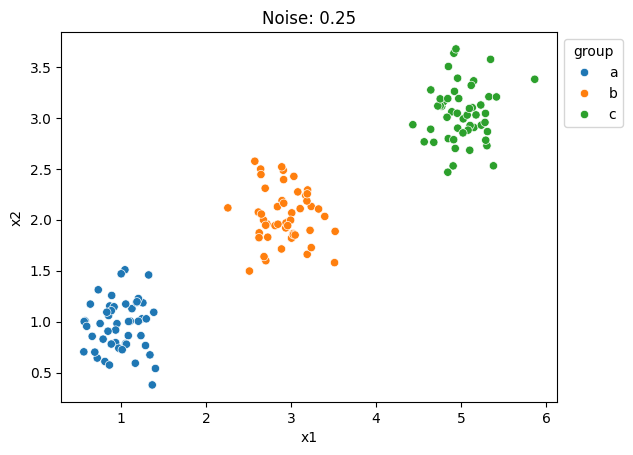

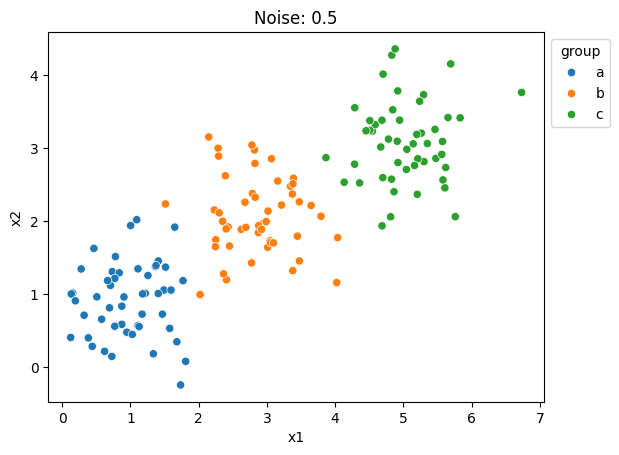

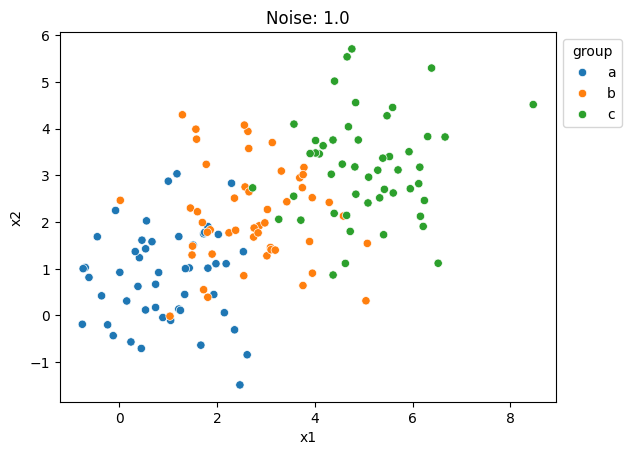

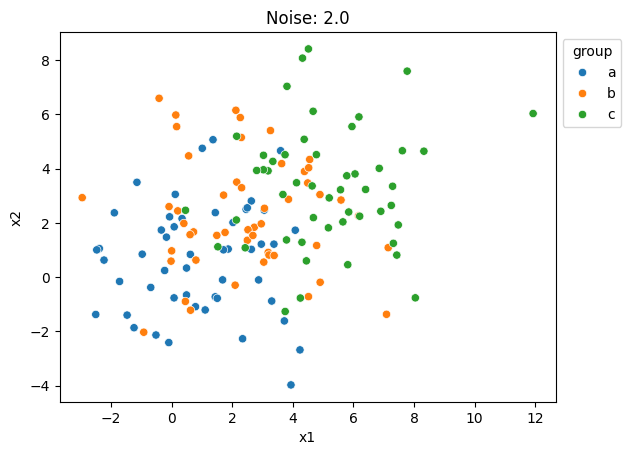

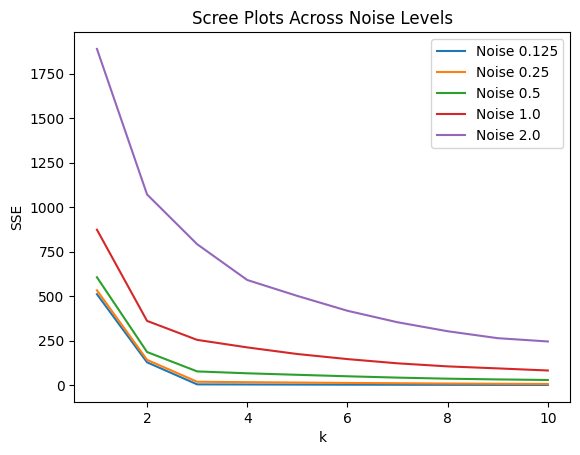

In [1]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# 2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
ax_0_125 = sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group")
sns.move_legend(ax_0_125, "upper left", bbox_to_anchor=(1, 1))
plt.title("Noise: 0.125")
plt.show()
ax_0_25 = sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group")
sns.move_legend(ax_0_25, "upper left", bbox_to_anchor=(1, 1))
plt.title("Noise: 0.25")
plt.show()
ax_0_5 = sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group")
sns.move_legend(ax_0_5, "upper left", bbox_to_anchor=(1, 1))
plt.title("Noise: 0.5")
plt.show()

ax_1_0 = sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group")
sns.move_legend(ax_1_0, "upper left", bbox_to_anchor=(1, 1))
plt.title("Noise: 1.0")
plt.show()

ax_2_0 = sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group")
sns.move_legend(ax_2_0, "upper left", bbox_to_anchor=(1, 1))
plt.title("Noise: 2.0")
plt.show()

# As the noise level goes up, the clusters become less distinct and more overlapping.

# 3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_125[["x1", "x2"]])
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="Noise 0.125")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_25[["x1", "x2"]])
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="Noise 0.25")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_5[["x1", "x2"]])
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="Noise 0.5")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df1_0[["x1", "x2"]])
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="Noise 1.0")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df2_0[["x1", "x2"]])
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="Noise 2.0")
plt.title("Scree Plots Across Noise Levels")
plt.xlabel("k")
plt.ylabel("SSE")
plt.legend()
plt.show()

# As the noise increases, the scree plot becomes less bend, flattens out, and the "elbow" becomes less distinct, harder to identify.
# Because the elbow is harder to identify with higher noises, it becomes harder to identify the optimal k.

# 4. Explain the intuition of the elbow, using this numerical simulation as an example.
# The elbow is used to determine the optimal number of k. As you increase the number of clusters, the model usually gets more accurate, 
# but at some point, the improvement becomes marginal. The "elbow" is where this marginal improvement stops, and it's a good indicator 
# of the optimal number of clusters balanced with the trade off between model complexity and performance.

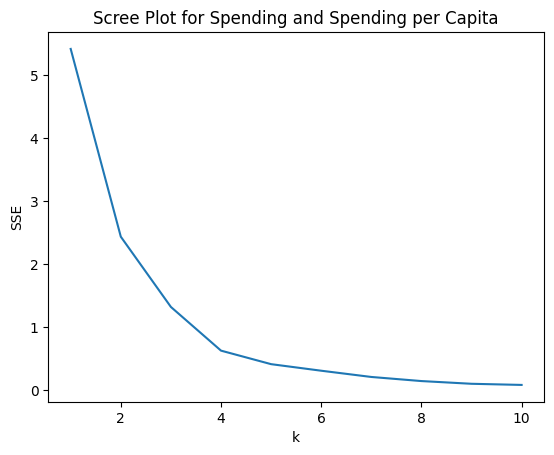

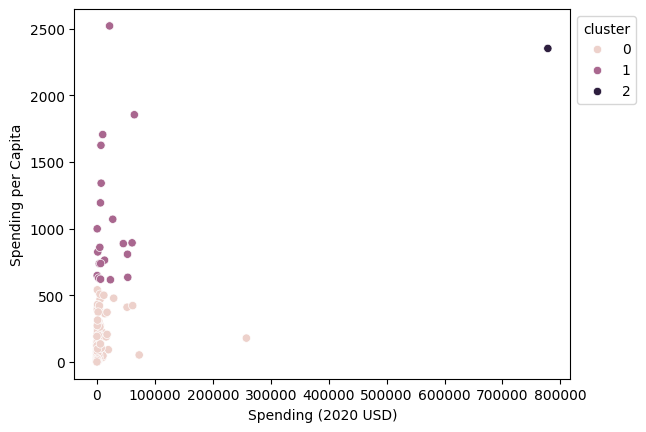

         index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0        126.0  2795.984127  1652.593453    32.0  1332.5  2769.0  4205.5   
1         21.0  2913.904762  1632.102874   236.0  1834.0  2922.0  4044.0   
2          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                  Year          ... Percent of Government Spending            \
            max  count    mean  ...                            75%       max   
cluster                         ...                                            
0        5880.0  126.0  2020.0  ...                       0.077917  0.303027   
1        5506.0   21.0  2020.0  ...                       0.110270  0.225050   
2        5540.0    1.0  2020.0  ...                       0.081976  0.081976   

        Spending per Capita                                   

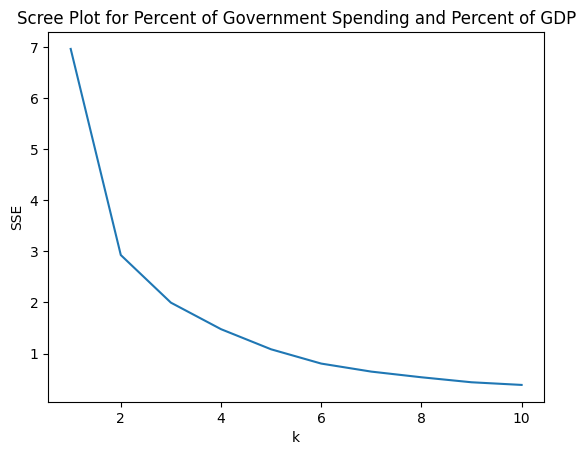

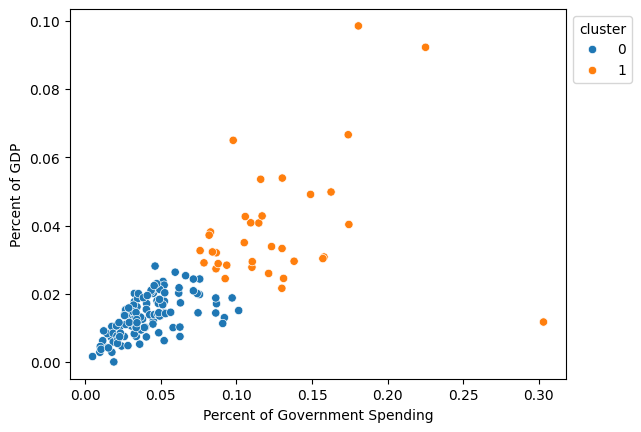

         index                                                           \
         count         mean          std    min     25%     50%     75%   
cluster                                                                   
0        113.0  2863.628319  1621.311342   32.0  1562.0  2888.0  4248.0   
1         35.0  2726.742857  1777.194225  100.0   899.0  2854.0  4061.0   

                  Year          ... Percent of Government Spending            \
            max  count    mean  ...                            75%       max   
cluster                         ...                                            
0        5880.0  113.0  2020.0  ...                       0.051496  0.101501   
1        5540.0   35.0  2020.0  ...                       0.143584  0.303027   

        Spending per Capita                                                \
                      count        mean         std        min        25%   
cluster                                                              

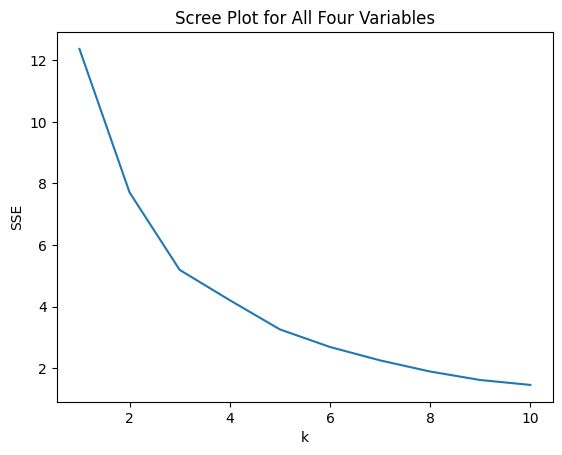

         index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0        111.0  2854.918919  1618.183489    32.0  1545.0  2888.0  4231.0   
1          6.0  4038.333333  1113.917352  2582.0  3202.5  4265.0  4613.5   
2         31.0  2512.903226  1789.866352   100.0   780.0  2514.0  3721.0   

                  Year          ... Percent of Government Spending            \
            max  count    mean  ...                            75%       max   
cluster                         ...                                            
0        5880.0  111.0  2020.0  ...                       0.050505  0.092044   
1        5540.0    6.0  2020.0  ...                       0.164503  0.225050   
2        5438.0   31.0  2020.0  ...                       0.134663  0.303027   

        Spending per Capita                                   

In [2]:
from sklearn.preprocessing import MinMaxScaler
# 1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
df_2020 = df[df["Year"] == 2020]
df_2020 = df_2020.dropna()
# I don't think further cleaning is required for this dataset.

# 2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
# Max min normalize
scaler = MinMaxScaler()
X_q2_scaled = scaler.fit_transform(
    df_2020[["Spending (2020 USD)", "Spending per Capita"]]
)

# Scree Plot
ks = range(1, 11)
sse_q2 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X_q2_scaled)
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=sse_q2).set(title="Scree Plot for Spending and Spending per Capita", xlabel="k", ylabel="SSE")
plt.show()

kmeans = KMeans(n_clusters=3, random_state=100, n_init=10).fit(X_q2_scaled)
df_2020["cluster"] = kmeans.labels_

# Scatter Plot
ax = sns.scatterplot(data=df_2020, x="Spending (2020 USD)", y="Spending per Capita", hue = "cluster")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

print(df_2020.groupby("cluster").describe())
us_cluster_q2 = df_2020[df_2020["Country"] == "United States of America"][
    "cluster"
].values[0]
print("\nUnited States is in Cluster:", us_cluster_q2)

# I notice that United States is in its own cluster. Because its spending is significantly higher than the other countries, 
# it forms its own cluster.Because k-means uses Euclidean distance, this massive gap forces the algorithm to create a dedicated cluster
# just for the US. Majority of the cluster are also in label 0, which spends the lowest in all the groups.

# 3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
# Max min normalize
scaler = MinMaxScaler()
X_q2_scaled = scaler.fit_transform(
    df_2020[["Percent of Government Spending", "Percent of GDP"]]
)

# Scree Plot
ks = range(1, 11)
sse_q2 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X_q2_scaled)
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=sse_q2).set(title="Scree Plot for Percent of Government Spending and Percent of GDP", xlabel="k", ylabel="SSE")
plt.show()

kmeans = KMeans(n_clusters=2, random_state=100, n_init=10).fit(X_q2_scaled)
df_2020["cluster"] = kmeans.labels_

# Scatter Plot
ax = sns.scatterplot(data=df_2020, x="Percent of Government Spending", y="Percent of GDP", hue = "cluster")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

print(df_2020.groupby("cluster").describe())
us_cluster_q2 = df_2020[df_2020["Country"] == "United States of America"][
    "cluster"
].values[0]
print("\nUnited States is in Cluster:", us_cluster_q2)
# I noticed that US is in label 1 along with 34 other countries. Here US has moderate data, therefore not skewing the graph and analysis.
# This normalizes the economic scale.

# 4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
X_q4_scaled = scaler.fit_transform(
    df_2020[["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]]
)
# Scree Plot
ks = range(1, 11)
sse_q4 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X_q4_scaled)
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=sse_q4).set(title="Scree Plot for All Four Variables", xlabel="k", ylabel="SSE")
plt.show()
kmeans = KMeans(n_clusters=3, random_state=100, n_init=10).fit(X_q4_scaled)
df_2020["cluster"] = kmeans.labels_

print(df_2020.groupby("cluster").describe())
us_cluster_q4 = df_2020[df_2020["Country"] == "United States of America"][
    "cluster"
].values[0]
print("\nUnited States is in Cluster:", us_cluster_q4)
# In question 2, US was completely separated from the other countries because of its high spending. In question 3, stripping away dollar
# amounts hid military strength, placing the US in a broad group alongside 38 other nations that spend around 2.7% of GDP. Here, combining the all 
# variables put US in a specific cluster with 5 other countries. This cluster indicates high per capita spending, high budget allocation, 
# and strong total military capacity.

# 5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?
# Yes it shows how feature selection and scaling can drastically change my analysis.When using absolute metrics (Spending USD and Spending
# per Capita), k - means highlighted how extreme outliers distort distance based algorithms. By switching to ratios, k means eliminated national 
# size bias

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [ff0af2d6ab8b9827524beaf1ef65367ad9727d62]
- **AI tool and model used:** [Gemini 3.6 Flash]

### *Prompts used

1. [[Datasheet and notebook attached]The assignment directions is in the notebook, I have completed the steps for phase 1, please give bullet point suggestions to make my code better or better completing the assignment]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. In Parts 3 and 4, you reuse df_2020["cluster"] = kmeans.labels_ directly on the same df_2020 dataframe without creating a copy or a suffix (like cluster_q3 or cluster_q4). This overwrites the cluster labels from previous parts in the dataframe, making it impossible to compare them side-by-side or inspect previous assignments if needed.
2. In Part 2, you generate both a scree plot and a scatter plot with hue. However, in Part 3 and Part 4, you generate scree plots and compute describe tables, but omit the scatter plots showing the resulting clusters on the 2D feature space.   

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I agree with what AI is saying, although creating separate columns for cluster is not needed for this assignment, it would be a good practice to keep a record of everything and not overwrite them |
| 2 | reject | I already have the scatter plot for part 3. Part 4 didn't ask for one. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# 2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
ax_0_125 = sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group")
sns.move_legend(ax_0_125, "upper left", bbox_to_anchor=(1, 1))
plt.title("Noise: 0.125")
plt.show()
ax_0_25 = sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group")
sns.move_legend(ax_0_25, "upper left", bbox_to_anchor=(1, 1))
plt.title("Noise: 0.25")
plt.show()
ax_0_5 = sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group")
sns.move_legend(ax_0_5, "upper left", bbox_to_anchor=(1, 1))
plt.title("Noise: 0.5")
plt.show()

ax_1_0 = sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group")
sns.move_legend(ax_1_0, "upper left", bbox_to_anchor=(1, 1))
plt.title("Noise: 1.0")
plt.show()

ax_2_0 = sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group")
sns.move_legend(ax_2_0, "upper left", bbox_to_anchor=(1, 1))
plt.title("Noise: 2.0")
plt.show()

# As the noise level goes up, the clusters become less distinct and more overlapping.

# 3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_125[["x1", "x2"]])
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="Noise 0.125")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_25[["x1", "x2"]])
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="Noise 0.25")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_5[["x1", "x2"]])
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="Noise 0.5")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df1_0[["x1", "x2"]])
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="Noise 1.0")

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df2_0[["x1", "x2"]])
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, label="Noise 2.0")
plt.title("Scree Plots Across Noise Levels")
plt.xlabel("k")
plt.ylabel("SSE")
plt.legend()
plt.show()

# As the noise increases, the scree plot becomes less bend, flattens out, and the "elbow" becomes less distinct, harder to identify.
# Because the elbow is harder to identify with higher noises, it becomes harder to identify the optimal k.

# 4. Explain the intuition of the elbow, using this numerical simulation as an example.
# The elbow is used to determine the optimal number of k. As you increase the number of clusters, the model usually gets more accurate, 
# but at some point, the improvement becomes marginal. The "elbow" is where this marginal improvement stops, and it's a good indicator 
# of the optimal number of clusters balanced with the trade off between model complexity and performance.

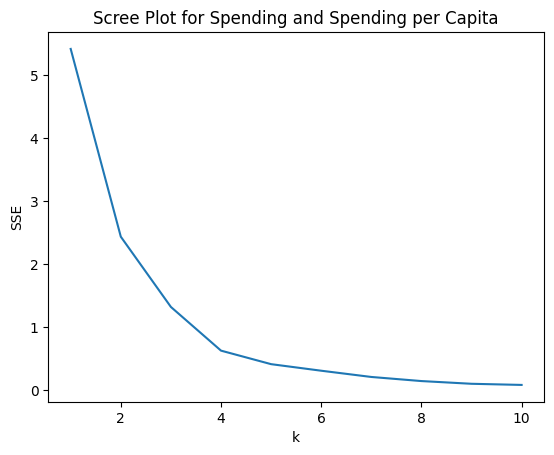

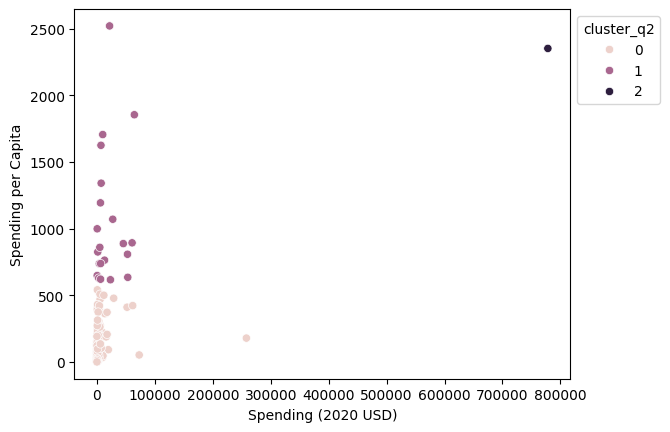

            index                                                            \
            count         mean          std     min     25%     50%     75%   
cluster_q2                                                                    
0           126.0  2795.984127  1652.593453    32.0  1332.5  2769.0  4205.5   
1            21.0  2913.904762  1632.102874   236.0  1834.0  2922.0  4044.0   
2             1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                     Year          ... Percent of Government Spending  \
               max  count    mean  ...                            75%   
cluster_q2                         ...                                  
0           5880.0  126.0  2020.0  ...                       0.077917   
1           5506.0   21.0  2020.0  ...                       0.110270   
2           5540.0    1.0  2020.0  ...                       0.081976   

                     Spending per Capita                           \
                 

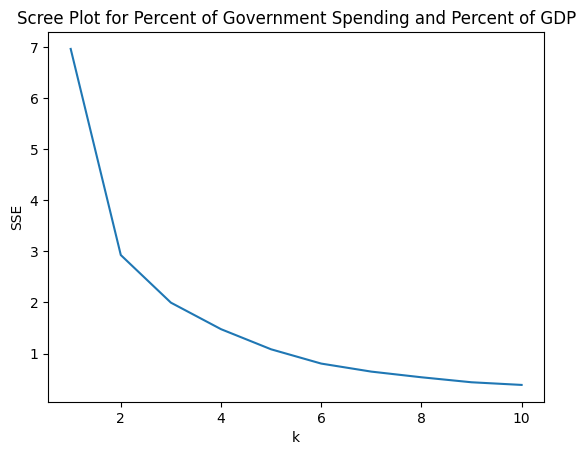

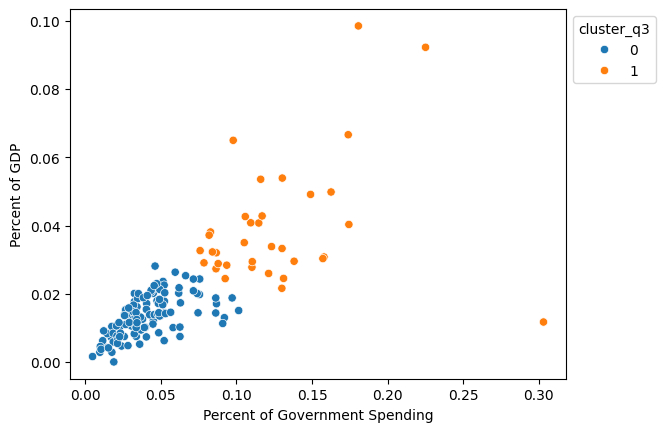

            index                                                           \
            count         mean          std    min     25%     50%     75%   
cluster_q3                                                                   
0           113.0  2863.628319  1621.311342   32.0  1562.0  2888.0  4248.0   
1            35.0  2726.742857  1777.194225  100.0   899.0  2854.0  4061.0   

                     Year          ... Spending per Capita               \
               max  count    mean  ...                 75%          max   
cluster_q3                         ...                                    
0           5880.0  113.0  2020.0  ...          303.716973  1341.058851   
1           5540.0   35.0  2020.0  ...          624.127089  2520.398541   

           cluster_q2                                               
                count      mean       std  min  25%  50%  75%  max  
cluster_q3                                                          
0               113.0  0.1

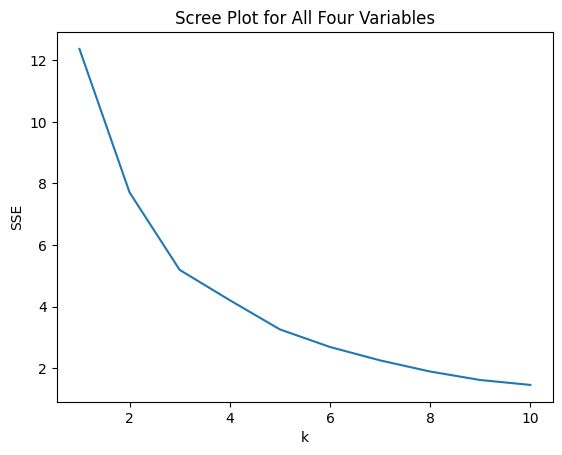

            index                                                            \
            count         mean          std     min     25%     50%     75%   
cluster_q4                                                                    
0           111.0  2854.918919  1618.183489    32.0  1545.0  2888.0  4231.0   
1             6.0  4038.333333  1113.917352  2582.0  3202.5  4265.0  4613.5   
2            31.0  2512.903226  1789.866352   100.0   780.0  2514.0  3721.0   

                     Year          ... cluster_q2      cluster_q3            \
               max  count    mean  ...        75%  max      count      mean   
cluster_q4                         ...                                        
0           5880.0  111.0  2020.0  ...        0.0  1.0      111.0  0.000000   
1           5540.0    6.0  2020.0  ...        1.0  2.0        6.0  1.000000   
2           5438.0   31.0  2020.0  ...        0.0  1.0       31.0  0.935484   

                                               
  

In [4]:
from sklearn.preprocessing import MinMaxScaler
# 1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
df_2020 = df[df["Year"] == 2020]
df_2020 = df_2020.dropna()
# I don't think further cleaning is required for this dataset.

# 2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
# Max min normalize
scaler = MinMaxScaler()
X_q2_scaled = scaler.fit_transform(
    df_2020[["Spending (2020 USD)", "Spending per Capita"]]
)

# Scree Plot
ks = range(1, 11)
sse_q2 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X_q2_scaled)
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=sse_q2).set(title="Scree Plot for Spending and Spending per Capita", xlabel="k", ylabel="SSE")
plt.show()

kmeans = KMeans(n_clusters=3, random_state=100, n_init=10).fit(X_q2_scaled)
df_2020["cluster_q2"] = kmeans.labels_

# Scatter Plot
ax = sns.scatterplot(data=df_2020, x="Spending (2020 USD)", y="Spending per Capita", hue = "cluster_q2")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

print(df_2020.groupby("cluster_q2").describe())
us_cluster_q2 = df_2020[df_2020["Country"] == "United States of America"][
    "cluster_q2"
].values[0]
print("\nUnited States is in Cluster:", us_cluster_q2)

# I notice that United States is in its own cluster. Because its spending is significantly higher than the other countries, 
# it forms its own cluster.Because k-means uses Euclidean distance, this massive gap forces the algorithm to create a dedicated cluster
# just for the US. Majority of the cluster are also in label 0, which spends the lowest in all the groups.

# 3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
# Max min normalize
scaler = MinMaxScaler()
X_q2_scaled = scaler.fit_transform(
    df_2020[["Percent of Government Spending", "Percent of GDP"]]
)

# Scree Plot
ks = range(1, 11)
sse_q2 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X_q2_scaled)
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=sse_q2).set(title="Scree Plot for Percent of Government Spending and Percent of GDP", xlabel="k", ylabel="SSE")
plt.show()

kmeans = KMeans(n_clusters=2, random_state=100, n_init=10).fit(X_q2_scaled)
df_2020["cluster_q3"] = kmeans.labels_

# Scatter Plot
ax = sns.scatterplot(data=df_2020, x="Percent of Government Spending", y="Percent of GDP", hue = "cluster_q3")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

print(df_2020.groupby("cluster_q3").describe())
us_cluster_q2 = df_2020[df_2020["Country"] == "United States of America"][
    "cluster_q3"
].values[0]
print("\nUnited States is in Cluster:", us_cluster_q2)
# I noticed that US is in label 1 along with 34 other countries. Here US has moderate data, therefore not skewing the graph and analysis.
# This normalizes the economic scale.

# 4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
X_q4_scaled = scaler.fit_transform(
    df_2020[["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]]
)
# Scree Plot
ks = range(1, 11)
sse_q4 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X_q4_scaled)
    .inertia_
    for k in ks
]
sns.lineplot(x=ks, y=sse_q4).set(title="Scree Plot for All Four Variables", xlabel="k", ylabel="SSE")
plt.show()
kmeans = KMeans(n_clusters=3, random_state=100, n_init=10).fit(X_q4_scaled)
df_2020["cluster_q4"] = kmeans.labels_

print(df_2020.groupby("cluster_q4").describe())
us_cluster_q4 = df_2020[df_2020["Country"] == "United States of America"][
    "cluster_q4"
].values[0]
print("\nUnited States is in Cluster:", us_cluster_q4)
# In question 2, US was completely separated from the other countries because of its high spending. In question 3, stripping away dollar
# amounts hid military strength, placing the US in a broad group alongside 38 other nations that spend around 2.7% of GDP. Here, combining the all 
# variables put US in a specific cluster with 5 other countries. This cluster indicates high per capita spending, high budget allocation, 
# and strong total military capacity.

# 5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?
# Yes it shows how feature selection and scaling can drastically change my analysis.When using absolute metrics (Spending USD and Spending
# per Capita), k - means highlighted how extreme outliers distort distance based algorithms. By switching to ratios, k means eliminated national 
# size bias

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]
The use of artificial intelligence pointed out minor flaws in my code and overall made it more readable and maintain good practice. In phase 1, I was able to successfully solve the problems stated, but improvements could have been made. These changes are reflected in my phase 2 of the assignment. For this assignment, I found AI benefits me a little, as the suggestion it gave didn't really improve the results, but more in developing good habits for cleaning and writing data. In the past assignments, AI assisted in streamlining my code and improving flow, but in this assignment it made less visible changes. The final solution was verified through me running the code adn manually checking the result. When it came to evaluating the changes that AI suggested, I accepted some task because it is good to not overwrite data. AI is limited in this case, as it didn't recognize the code for my scatterplot for question 3 and asked me to put one on there.